# Netflix Content Analytics

**Goal.** Describe how Netflix's catalogue is composed and how it changed, and turn the patterns into questions a content-strategy team could act on.

**Data.** 7,787 titles (movies and TV shows) with type, country, genres, rating, runtime, director and the date each title was added. It is a public Kaggle dataset and covers titles added up to 16 January 2021.

**Questions**
1. How fast did the catalogue grow, and is it seasonal?
2. How international is it, and did that change?
3. How fresh is new content: current releases or back catalogue?
4. Who is the content for? Has the age-rating mix shifted?
5. Does each country specialise in particular genres?
6. What do formats look like: movie runtime, TV season counts?
7. How concentrated is the directing talent?

**Important limit.** The data has no viewership numbers. Everything below describes what was *in* the catalogue, not what people watched.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))   # run from notebooks/

import pandas as pd
from IPython.display import Image, display

from netflix_analytics import analysis as A
from netflix_analytics import clean, data_quality_report, load_raw, quality_summary
from netflix_analytics import figures as F

pd.set_option("display.max_columns", 30)
OUT = Path("figures_tmp"); OUT.mkdir(exist_ok=True)

## 1. Load and check data quality

In [2]:
raw = load_raw("../data/netflix_titles.csv")
df = clean(raw)
quality = quality_summary(raw, df)
quality

{'rows_raw': 7787,
 'rows_clean': 7786,
 'duplicates_removed': 1,
 'missing_country': 507,
 'missing_director': 2389,
 'missing_cast': 718,
 'missing_date_added': 10,
 'missing_rating': 7,
 'added_before_release': 12,
 'unparsed_dates': 0}

In [3]:
data_quality_report(raw).head(6)

,missing,missing_pct
director,2389,30.68
cast,718,9.22
country,507,6.51
date_added,10,0.13
rating,7,0.09
title,0,0.00


**What the checks found**
- 1 exact duplicate row (`Consequences`, IDs s1486 and s1487) was removed, leaving 7,786 titles.
- 507 titles (6.5%) have no country and 2,389 (30.7%) have no director.
- 12 titles have a date added earlier than their release year (likely pre-release listings); they are kept.

**Cleaning decision.** Missing values are labelled `Unknown` rather than filled with the most common value. Filling country with the mode would label 507 unknown titles as "United States" and inflate the US count by about 18%.

## 2. Growth and seasonality

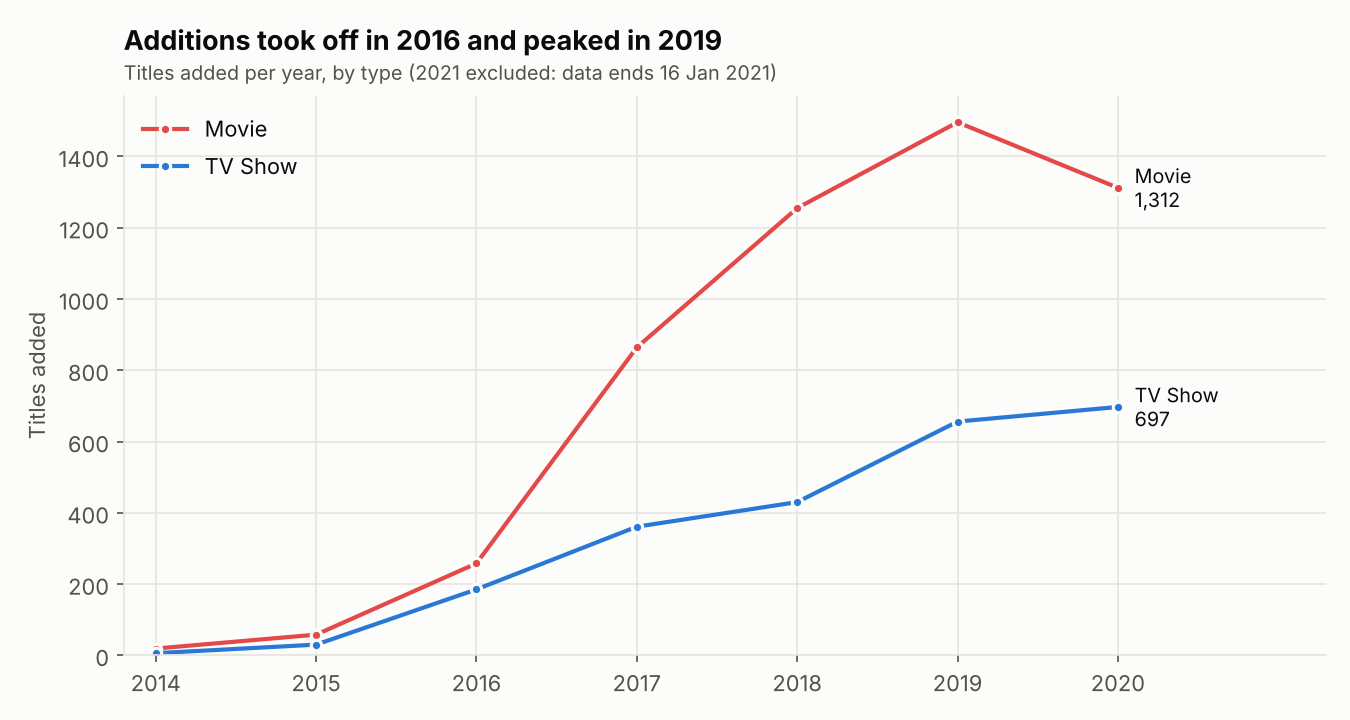

,Movie,TV Show
year_added,,
2015,58,30
2016,258,185
2017,864,361
2018,1255,430
2019,1496,656
2020,1312,697


In [4]:
display(Image(F.growth_by_type(df, OUT)))
A.titles_added_per_year(df).tail(6)

Additions took off in 2016 and peaked in 2019 (2,152 titles). The 2021 row is left out because the data stops on 16 January 2021, so it only covers a fraction of the year. Movies outnumber TV shows every year, but TV additions kept growing in 2020 while movie additions fell.

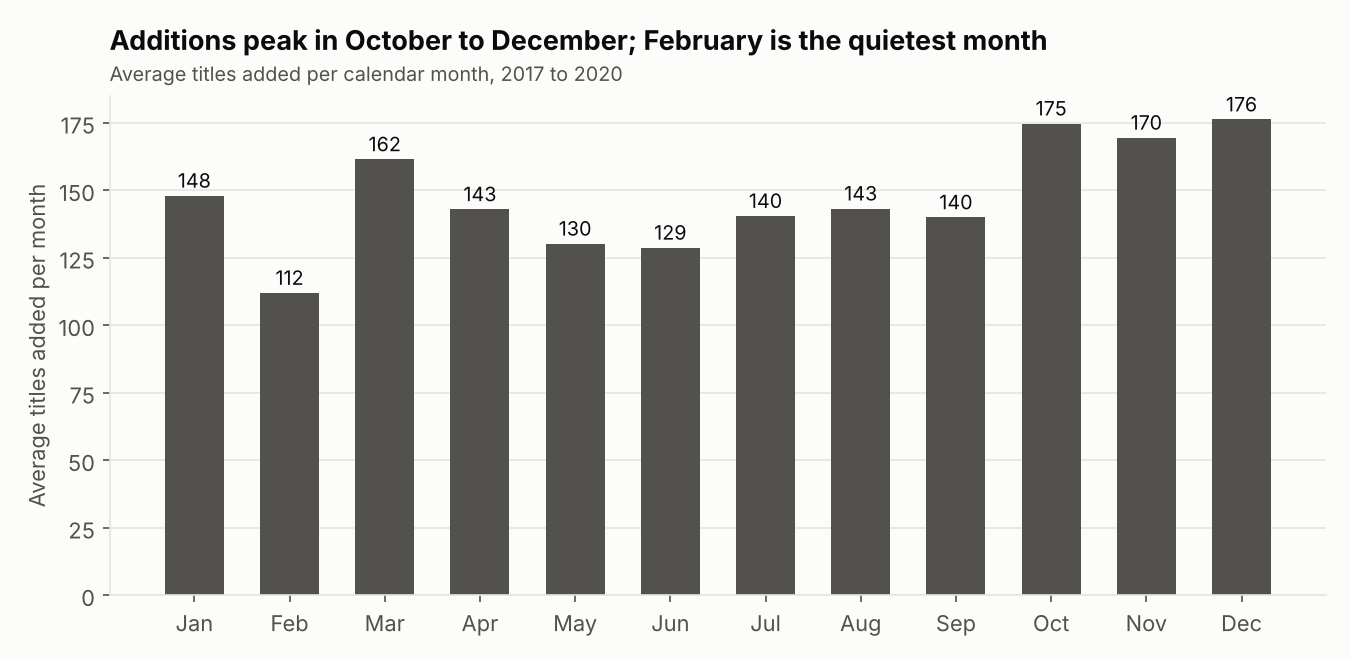

In [5]:
display(Image(F.seasonality(df, OUT)))

Averaged over 2017 to 2020, October to December are the busiest months (about 170 to 176 titles a month) and February is the quietest (112). With only four years of data this is a pattern to watch, not a firm rule.

## 3. Geography: how international is the catalogue?

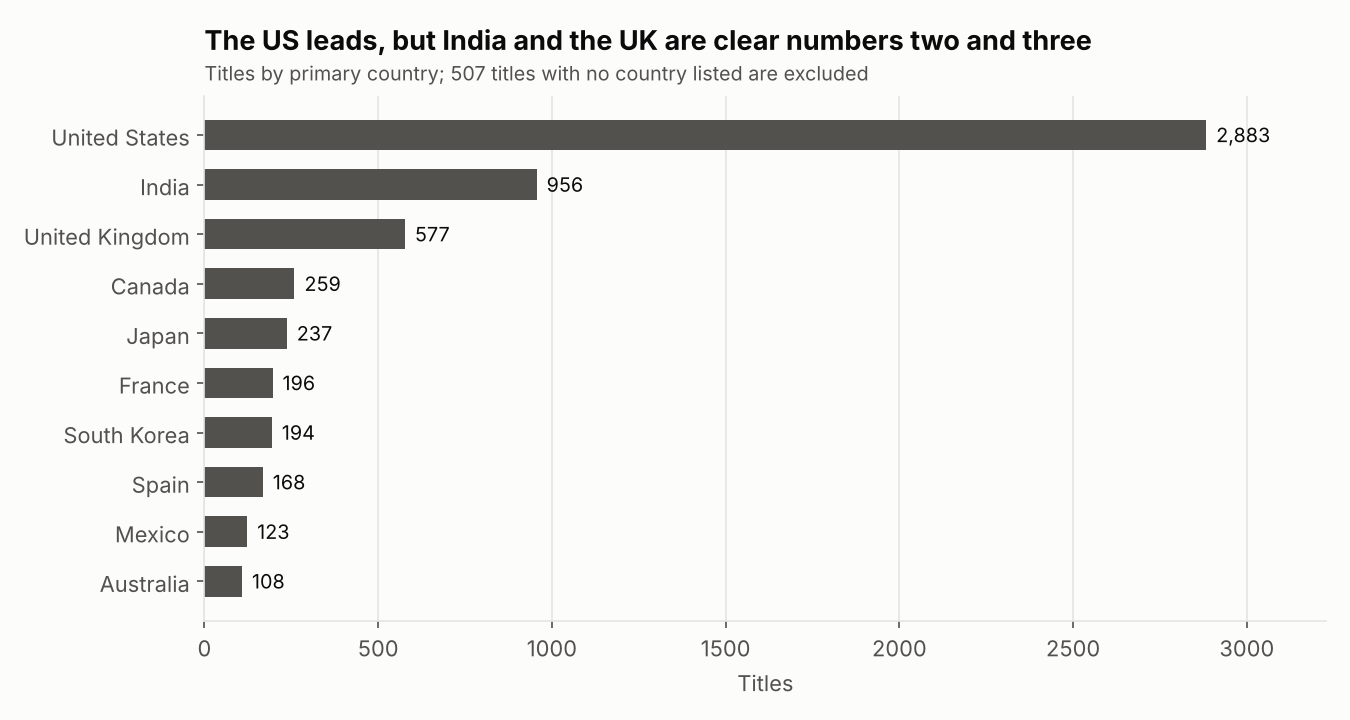

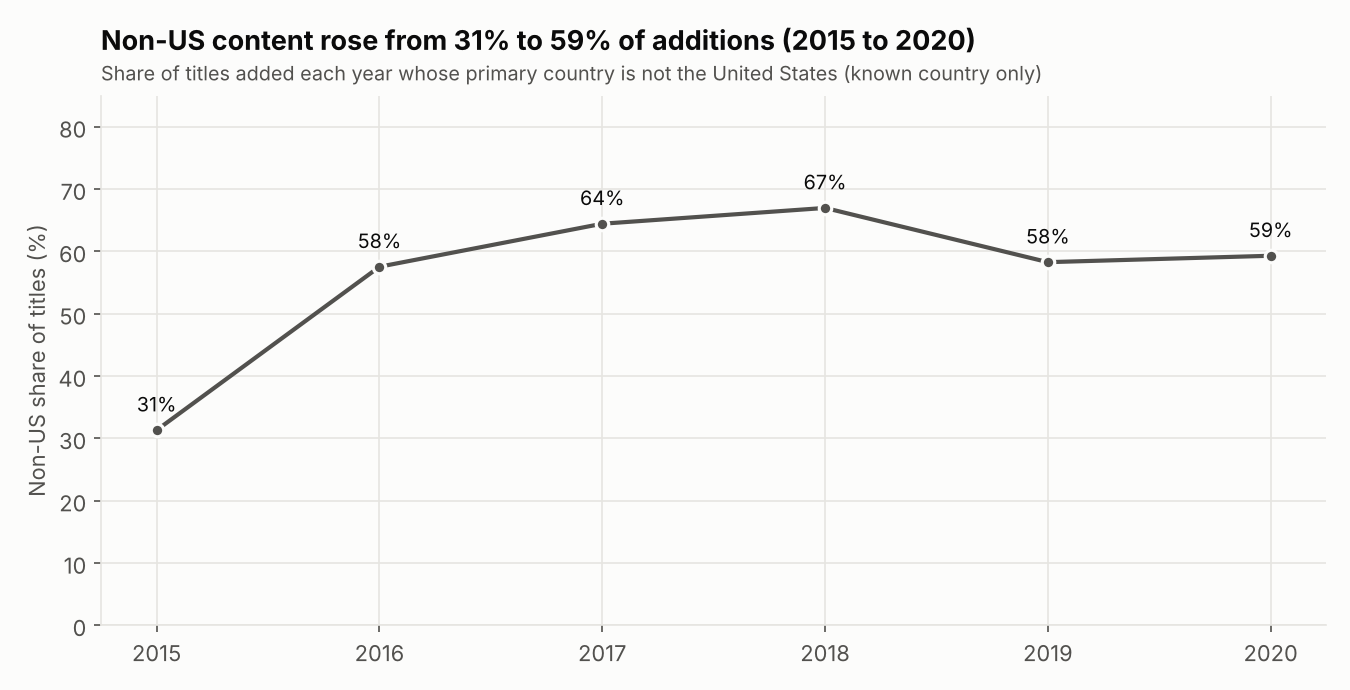

{'early_share': 0.2773109243697479,
 'late_share': 0.6268561731014001,
 'p_value': 1.9170256780601557e-14}

In [6]:
display(Image(F.top_countries(df, OUT)))
display(Image(F.international_share(df, OUT)))
A.non_us_shift_test(df)

The US is the largest source with 2,883 titles, followed by India (956) and the UK (577). The more interesting change is over time: the **non-US share of new additions rose from 28% in 2013-2015 to 63% in 2017-2019**. A chi-square test on the two periods gives p < 0.001, so this is not noise. The share has since levelled off at about 58-59%.

## 4. Freshness: current releases or back catalogue?

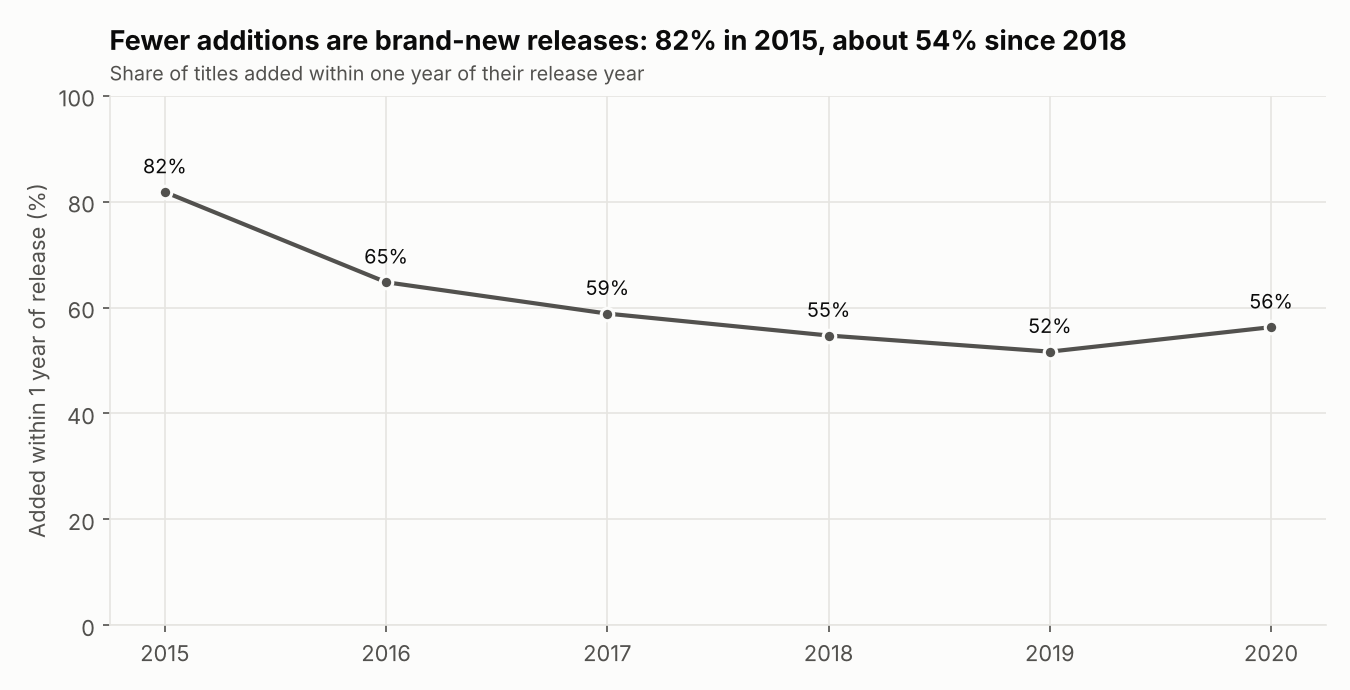

,titles,new_share,median_age
year_added,,,
2015,88,0.82,0.0
2016,443,0.65,1.0
2017,1225,0.59,1.0
2018,1685,0.55,1.0
2019,2152,0.52,1.0
2020,2009,0.56,1.0


In [7]:
display(Image(F.freshness(df, OUT)))
A.freshness_by_year(df).round(2)

In 2015, 82% of titles were added within a year of release. Since 2018 it is about 54%, so nearly half of new additions are older titles. This is consistent with a growing back catalogue, but the data cannot say whether those titles were licensed or produced earlier.

## 5. Audience: who is the content for?

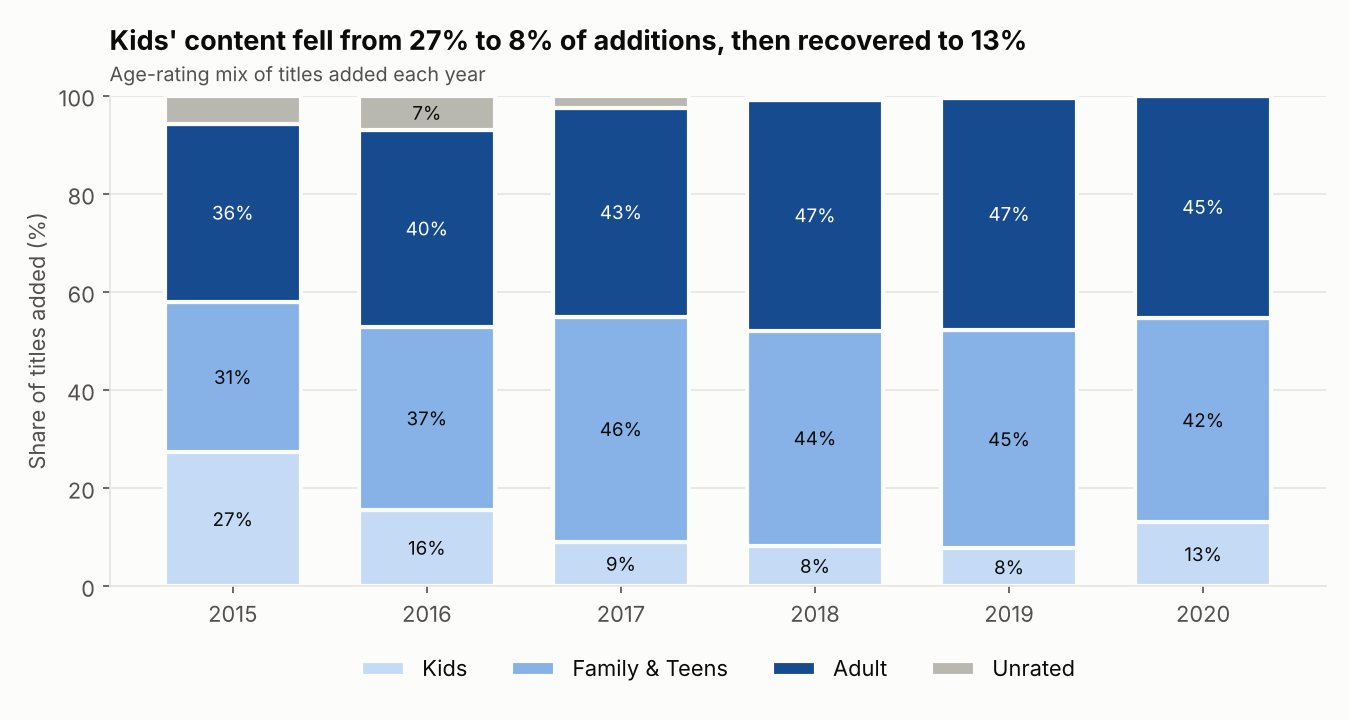

In [8]:
display(Image(F.rating_mix(df, OUT)))

Kids' content (TV-Y, TV-Y7, TV-G, G) fell from 27% of additions in 2015 to 8% in 2018-2019, then recovered to 13% in 2020. Adult-rated titles (TV-MA, R, NC-17) are now the largest group at 45%. Note that 2015 is a small base (88 titles), so the starting point is less reliable than later years.

## 6. Do countries specialise in genres?

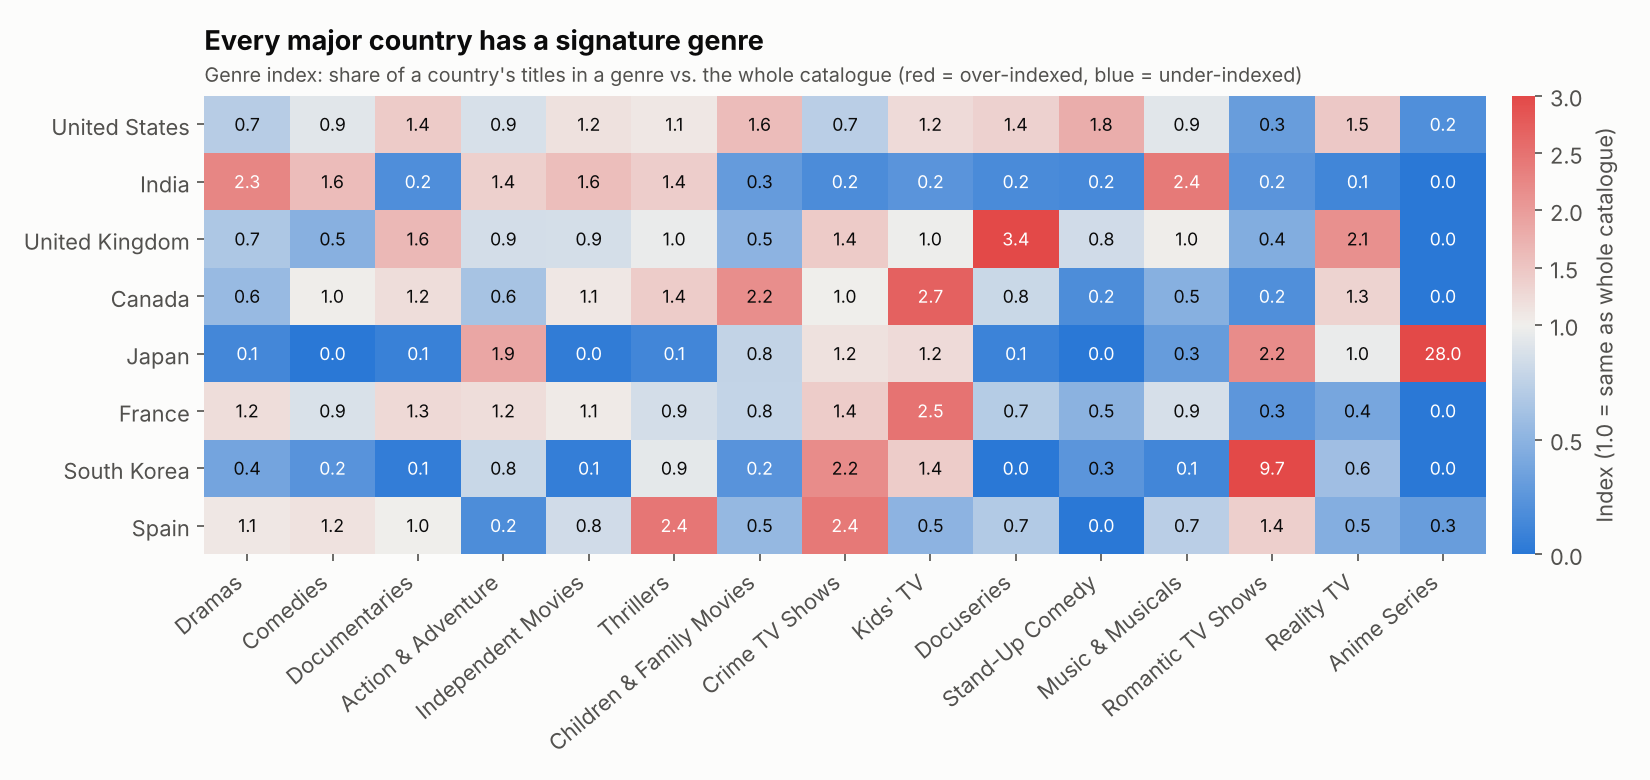

South Korea {'genre': 'Romantic TV Shows', 'lift': 9.747349304765747, 'country_share': 0.37628865979381443, 'overall_share': 0.03860420387415854}
India {'genre': 'Music & Musicals', 'lift': 2.4017368228918032, 'country_share': 0.09832635983263599, 'overall_share': 0.04093968951779091}
United Kingdom {'genre': 'Docuseries', 'lift': 3.414956562054996, 'country_share': 0.14731369150779897, 'overall_share': 0.04313779365297431}
Japan {'genre': 'Anime Features', 'lift': 29.096602265156562, 'country_share': 0.22784810126582278, 'overall_share': 0.007830745981590878}


In [9]:
display(Image(F.country_genre_heatmap(df, OUT)))
for c in ["South Korea", "India", "United Kingdom", "Japan"]:
    print(c, A.signature_genre(df, c))

Each country has a clear signature, using a genre index (share of the country's titles in a genre divided by the share across the whole catalogue):

- **South Korea:** Romantic TV Shows are 38% of its titles against 3.9% overall (9.7x), plus Crime TV Shows at 2.2x.
- **Japan:** Anime Features are 23% of its titles against 0.8% overall.
- **United Kingdom:** Docuseries are 15% of its titles against 4.3% overall (3.4x).
- **India:** Dramas (2.3x) and Music & Musicals (2.4x).

"International Movies" and "International TV Shows" are excluded here because they are geography tags, not genres, so any non-US country would trivially over-index on them.

## 7. Formats and talent

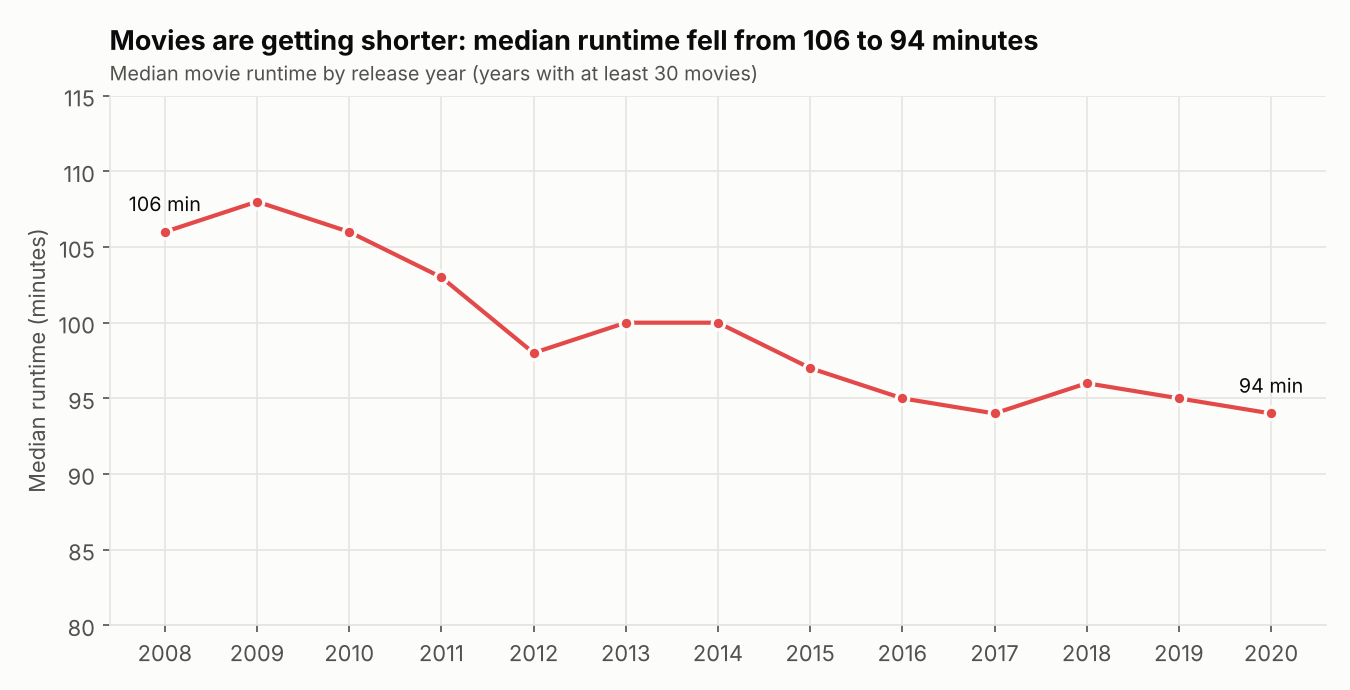

{'rho': -0.18499781344738905, 'p_value': 1.8960762877452855e-39, 'movies': 4962}


,shows,one_season_share,avg_seasons
period,,,
2010 or earlier,211,0.66,2.22
2011-2015,414,0.72,1.64
2016-2018,895,0.67,1.71
2019-2021,890,0.63,1.8


In [10]:
display(Image(F.runtime_trend(df, OUT)))
print(A.runtime_trend_test(df))
A.seasons_by_release_period(df).round(2)

Median movie runtime fell from 106 minutes (2008 releases) to 94 minutes (2020). A Spearman test on 2000-2020 releases confirms a negative relationship (rho = -0.18, p < 0.001), but it is weak: release year explains little of the variation in runtime.

Between 63% and 72% of TV shows have a single season in **every** release period, including shows released before 2010. So the dominance of one-season shows is not simply because many shows are new.

In [11]:
print(A.director_concentration(df))
A.top_directors(df)

{'unique_directors': 4478, 'titles_with_director': 5397, 'top_10_share_of_credits': 0.02273470722930978, 'directors_with_one_title_share': 0.8054935238945958}


directors
Jan Suter              21
Raúl Campos            19
Marcus Raboy           16
Jay Karas              15
Cathy Garcia-Molina    13
Youssef Chahine        12
Martin Scorsese        12
Jay Chapman            12
Steven Spielberg       10
Shannon Hartman         9
Name: count, dtype: int64

The directing talent is highly fragmented: 4,478 directors appear, 81% directed only one title, and the ten most prolific directors account for just 2.3% of credits. The catalogue does not depend on a small set of directors. About 31% of titles have no director listed.

## 8. What this suggests

These are hypotheses a content team could test with viewing data, not conclusions.

| Finding | Question to follow up |
|---|---|
| Non-US share doubled from 2015 to 2017 and then plateaued | Is the plateau a deliberate balance, or did regional growth slow? |
| Strong country specialties (Korean romance, Japanese anime, UK docuseries) | Do viewers outside those countries watch those genres, i.e. does specialty content travel? |
| Kids' share dropped sharply after 2015 | Is the family segment under-served, and does viewing data show demand? |
| Nearly half of additions are older titles | How does the performance of back-catalogue titles compare with new releases? |
| Additions peak in Q4 and dip in February | Do release dates match viewing peaks, or is the schedule driven by licensing windows? |

## Limitations
- **No viewership data.** "Top" means most titles, not most watched.
- **Snapshot and survivorship bias.** Titles that left the catalogue before the snapshot are missing.
- **First country only.** Co-productions count once, under the first listed country.
- **Incomplete final year.** 2021 is excluded from trends.
- **Missing fields.** 6.5% of titles lack a country and 30.7% lack a director; results for those fields describe only the titles that have them.